# Practica M36 — Simulación Monte Carlo de un presupuesto

#### **Objetivo:** calcular el costo de un pequeño proyecto de equipamiento de oficina. Primero crearemos un presupuesto fijo (modelo determinístico) y después consideraremos la incertidumbre de los precios mediante **5,000 simulaciones**. Compararemos las distribuciones **normal** y **triangular**, interpretaremos los resultados y analizaremos la sensibilidad del presupuesto.

## 1. Modelo determinístico

Cada ítem tiene una cantidad fija y un precio unitario estimado. El **costo total** es la suma de `cantidad × precio unitario` de cada ítem. Las cantidades se mantienen constantes durante este ejercicio; solo cambiaremos los precios.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos sencillos de un proyecto de equipamiento de oficina
items = ["Computadoras", "Escritorios", "Sillas", "Instalación"]
cantidades = np.array([4, 6, 6, 1])
precios = np.array([900.0, 250.0, 110.0, 700.0])

presupuesto = pd.DataFrame({
    "Ítem": items,
    "Cantidad": cantidades,
    "Precio unitario": precios
})
presupuesto["Subtotal"] = presupuesto["Cantidad"] * presupuesto["Precio unitario"]
costo_base = presupuesto["Subtotal"].sum()

print(presupuesto.to_string(index=False))
print(f"\nCosto determinístico total: ${costo_base:,.2f}")

        Ítem  Cantidad  Precio unitario  Subtotal
Computadoras         4            900.0    3600.0
 Escritorios         6            250.0    1500.0
      Sillas         6            110.0     660.0
 Instalación         1            700.0     700.0

Costo determinístico total: $6,460.00


## 2. Asignación de distribuciones de probabilidad

Supondremos dos maneras diferentes de representar la variación de los precios:

- **Normal:** cada precio tiene como media su estimación y desviación estándar del **10 %**. Con `np.maximum` impedimos precios negativos, aunque en este ejemplo serían muy improbables.
- **Triangular:** el precio mínimo es el **80 %**, el más probable es el **100 %** y el máximo es el **120 %** del estimado. Es útil cuando conocemos un rango y un valor más probable.

Usaremos una semilla para que los resultados puedan reproducirse.

In [2]:
iteraciones = 5000
rng_normal = np.random.default_rng(36)
rng_triangular = np.random.default_rng(36)

# Cada matriz tiene 5000 filas (simulaciones) y 4 columnas (ítems).
precios_normal = rng_normal.normal(
    loc=precios,
    scale=precios * 0.10,
    size=(iteraciones, len(items))
)
precios_normal = np.maximum(precios_normal, 0)

precios_triangular = rng_triangular.triangular(
    left=precios * 0.80,
    mode=precios,
    right=precios * 1.20,
    size=(iteraciones, len(items))
)

print("Dimensiones de cada simulación:", precios_normal.shape)
print("Primeros precios simulados con distribución normal:")
print(np.round(precios_normal[:3], 2))

Dimensiones de cada simulación: (5000, 4)
Primeros precios simulados con distribución normal:
[[ 800.12  242.8   107.11  683.42]
 [1000.69  253.33  113.95  700.41]
 [ 819.14  254.3   117.99  708.21]]


## 3. Simulación Monte Carlo con 5,000 iteraciones

Para cada simulación multiplicamos los precios aleatorios por las cantidades fijas y sumamos los cuatro ítems. Cada total representa **un posible costo del proyecto**.

In [3]:
costos_items_normal = precios_normal * cantidades
costos_items_triangular = precios_triangular * cantidades

totales_normal = np.sum(costos_items_normal, axis=1)
totales_triangular = np.sum(costos_items_triangular, axis=1)

print("Iteraciones normales:", len(totales_normal))
print("Primeros 5 costos simulados (normal):", np.round(totales_normal[:5], 2))
print("Primeros 5 costos simulados (triangular):", np.round(totales_triangular[:5], 2))

Iteraciones normales: 5000
Primeros 5 costos simulados (normal): [5983.34 6906.83 6218.48 6131.65 6005.2 ]
Primeros 5 costos simulados (triangular): [6197.42 6684.91 6066.59 6694.85 6196.83]


## 4. Lectura e interpretación de resultados

- **Media:** costo esperado en este modelo.
- **Mediana:** costo que deja aproximadamente el 50 % de las simulaciones por debajo.
- **Percentil 90 (P90):** monto que cubre aproximadamente el 90 % de los costos simulados.
- **Probabilidad de exceder el presupuesto:** proporción de simulaciones cuyo costo supera el límite indicado.

Como referencia, fijaremos un límite de presupuesto con **10 % de contingencia** sobre el costo determinístico.

In [4]:
limite_presupuesto = costo_base * 1.10

def resumen_simulacion(totales, nombre):
    return {
        "Distribución": nombre,
        "Media": np.mean(totales),
        "Mediana": np.median(totales),
        "Desv. estándar": np.std(totales),
        "P10": np.percentile(totales, 10),
        "P90": np.percentile(totales, 90),
        "P(superar límite) %": np.mean(totales > limite_presupuesto) * 100
    }

resultados = pd.DataFrame([
    resumen_simulacion(totales_normal, "Normal"),
    resumen_simulacion(totales_triangular, "Triangular")
])

print(f"Costo base: ${costo_base:,.2f}")
print(f"Límite (+10 %): ${limite_presupuesto:,.2f}")
print(resultados.round(2).to_string(index=False))

Costo base: $6,460.00
Límite (+10 %): $7,106.00
Distribución   Media  Mediana  Desv. estándar     P10     P90  P(superar límite) %
      Normal 6456.83  6462.05          406.06 5940.85 6978.27                 5.32
  Triangular 6458.99  6456.23          323.25 6029.01 6882.35                 1.94


### 4.1 ¿Qué nos dicen los resultados del presupuesto?

El **costo fijo de referencia es $6,460.00** y, al agregar una contingencia del 10 %, el límite disponible sería **$7,106.00**. La media de las 5,000 simulaciones quedó muy cerca del costo base en ambos casos: **$6,456.83** con la distribución normal y **$6,458.99** con la triangular. Las medianas también son parecidas (**$6,462.05** y **$6,456.23**, respectivamente). Esto sugiere que, en promedio, el presupuesto inicial representa bien el centro de ambos escenarios, pero **no significa que todos los proyectos cuesten esa cantidad**.

La diferencia importante está en la variabilidad. La **desviación estándar** de la normal es **$406.06**, mayor que los **$323.25** de la triangular. El intervalo entre **P10 y P90** va de **$5,940.85 a $6,978.27** para la normal, frente a **$6,029.01 a $6,882.35** para la triangular. Por lo tanto, el escenario normal contempla costos más dispersos y un rango mayor de resultados posibles.

El **P90 de $6,978.27 (normal)** indica que aproximadamente el 90 % de las simulaciones quedó en ese valor o por debajo; en la triangular, el P90 fue **$6,882.35**. Frente al límite de $7,106.00, la probabilidad estimada de excederlo es de **5.32 % con la normal** y **1.94 % con la triangular**. En términos sencillos, con este modelo la reserva del 10 % cubriría alrededor del **94.68 %** y **98.06 %** de los escenarios, respectivamente. Son estimaciones de la simulación, no garantías.

**Interpretación para el proyecto:** la contingencia del 10 % parece razonable bajo los supuestos utilizados, aunque la distribución normal recomienda ser más cuidadosos porque presenta un riesgo de sobrecosto mayor. Antes de aprobar el presupuesto habría que comprobar que los rangos de precios elegidos se parecen a los de proveedores reales.

## 5. Visualización básica

El histograma muestra cuántas veces aparece cada intervalo de costo simulado. La línea vertical representa el **costo determinístico**. No todos los escenarios producen el mismo resultado: Monte Carlo permite ver un rango de posibilidades.

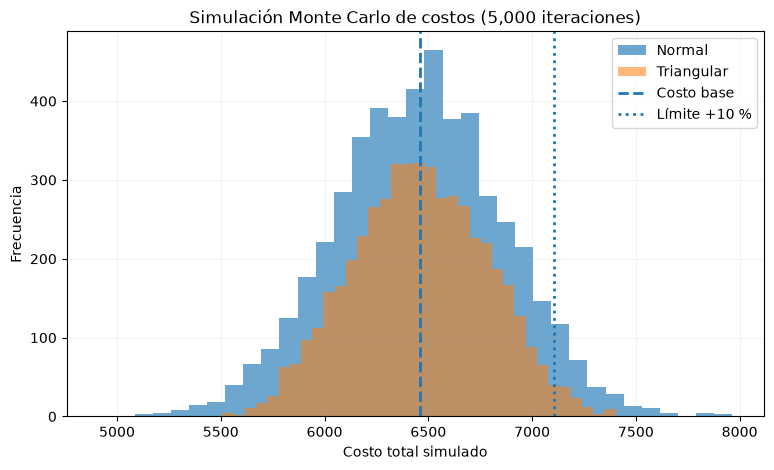

In [5]:
plt.figure(figsize=(9, 5))
plt.hist(totales_normal, bins=35, alpha=0.65, label="Normal")
plt.hist(totales_triangular, bins=35, alpha=0.55, label="Triangular")
plt.axvline(costo_base, linestyle="--", linewidth=2, label="Costo base")
plt.axvline(limite_presupuesto, linestyle=":", linewidth=2, label="Límite +10 %")
plt.title("Simulación Monte Carlo de costos (5,000 iteraciones)")
plt.xlabel("Costo total simulado")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid(alpha=0.15)
plt.show()

### Lectura del histograma

En el histograma se observa que **ambas distribuciones se concentran cerca del costo base de $6,460**, pero la normal se extiende más hacia costos bajos y altos, mientras que la triangular permanece más concentrada alrededor del presupuesto esperado. La línea del límite de **$7,106** permite visualizar que algunos resultados simulados lo superan, especialmente en el escenario normal.

Esto significa que, aunque los dos modelos generan costos medios similares, **la distribución elegida cambia el riesgo** que debe contemplarse al reservar dinero para el proyecto.

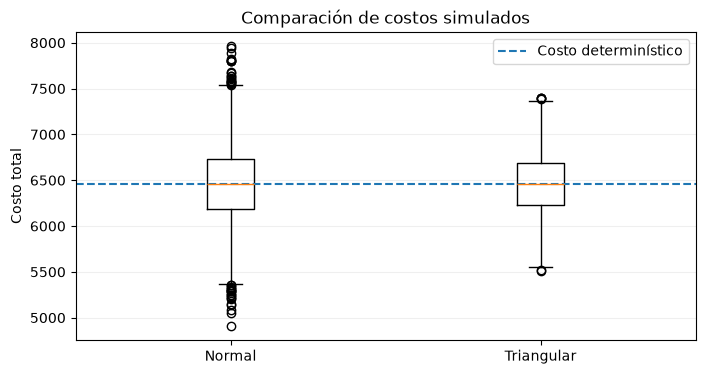

In [6]:
plt.figure(figsize=(8, 4))
plt.boxplot([totales_normal, totales_triangular], tick_labels=["Normal", "Triangular"])
plt.axhline(costo_base, linestyle="--", label="Costo determinístico")
plt.title("Comparación de costos simulados")
plt.ylabel("Costo total")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.show()

### Lectura del diagrama de caja (boxplot)

El boxplot confirma la diferencia de dispersión: la **distribución normal presenta una caja y una extensión de valores más amplias** que la triangular, mientras que las medianas permanecen cerca del costo determinístico. Por tanto, la triangular representa un presupuesto relativamente más estable bajo el rango de precios del 80 % al 120 %.

Para la toma de decisiones, el gráfico indica que **no basta con comparar promedios**; también es importante considerar la amplitud de los posibles sobrecostos.

## 6. Análisis de sensibilidad

### 6.1 Sensibilidad al tipo de distribución

Comparamos la dispersión, los percentiles y el porcentaje de simulaciones que superan el límite. Ambos escenarios parten de los **mismos precios estimados**, pero representan la incertidumbre de forma diferente. El objetivo no es afirmar que una distribución es universalmente correcta: depende de la información disponible del proyecto.

Distribución   Media  Desv. estándar     P90  P(superar límite) %
      Normal 6456.83          406.06 6978.27                 5.32
  Triangular 6458.99          323.25 6882.35                 1.94


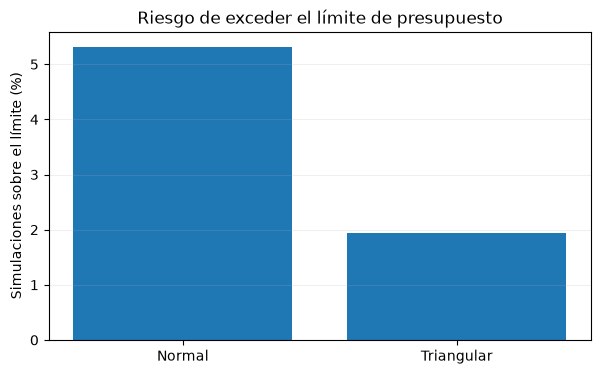

In [7]:
comparacion = resultados[["Distribución", "Media", "Desv. estándar", "P90", "P(superar límite) %"]].copy()
print(comparacion.round(2).to_string(index=False))

plt.figure(figsize=(7, 4))
plt.bar(comparacion["Distribución"], comparacion["P(superar límite) %"])
plt.title("Riesgo de exceder el límite de presupuesto")
plt.ylabel("Simulaciones sobre el límite (%)")
plt.grid(axis="y", alpha=0.2)
plt.show()

### Lectura de la sensibilidad por distribución

La gráfica de riesgo muestra **5.32 %** de simulaciones por encima del límite para la normal, frente a **1.94 %** para la triangular: una diferencia de **3.38 puntos porcentuales**. Aunque ambos escenarios parten de los mismos precios y cantidades, **la normal genera mayor riesgo de exceder la contingencia del 10 %** porque admite una variación más amplia de precios.

La elección entre normal y triangular debe basarse en la información disponible sobre precios; no podemos concluir que la triangular sea siempre más realista solo porque produzca menos riesgo.

### 6.2 Sensibilidad por ítem

Para identificar qué variable tiene más impacto, aumentaremos **solo el precio de un ítem un 10 %**, dejando los demás precios constantes. Después calcularemos el cambio en el costo del presupuesto base. Es una prueba sencilla *uno a la vez*; no necesita generar otras 5,000 simulaciones.

        Ítem  Aumento del costo (+10 % precio)
Computadoras                             360.0
 Escritorios                             150.0
 Instalación                              70.0
      Sillas                              66.0


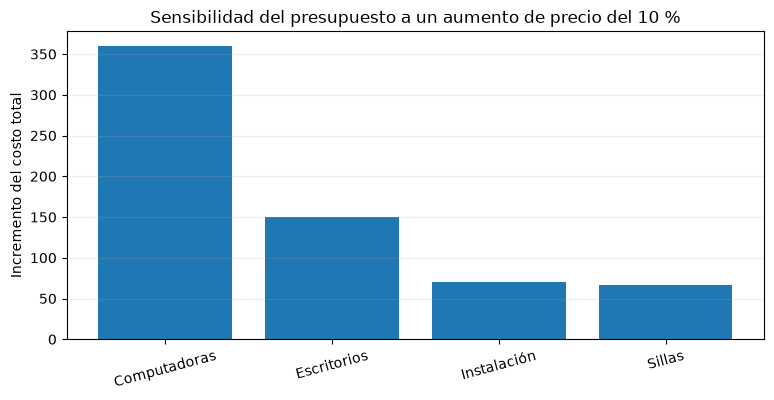

In [8]:
impactos = []
for i, item in enumerate(items):
    precios_modificados = precios.copy()
    precios_modificados[i] = precios_modificados[i] * 1.10
    nuevo_total = np.sum(cantidades * precios_modificados)
    impactos.append(nuevo_total - costo_base)

sensibilidad = pd.DataFrame({"Ítem": items, "Aumento del costo (+10 % precio)": impactos})
sensibilidad = sensibilidad.sort_values("Aumento del costo (+10 % precio)", ascending=False)
print(sensibilidad.round(2).to_string(index=False))

plt.figure(figsize=(9, 4))
plt.bar(sensibilidad["Ítem"], sensibilidad["Aumento del costo (+10 % precio)"])
plt.title("Sensibilidad del presupuesto a un aumento de precio del 10 %")
plt.ylabel("Incremento del costo total")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.2)
plt.show()

### 6.3 Lectura de la sensibilidad por ítem

Al aumentar **10 % el precio unitario de un solo ítem**, el presupuesto crece **$360** por las computadoras, **$150** por los escritorios, **$70** por la instalación y **$66** por las sillas. **Las computadoras tienen el mayor impacto**, porque su subtotal original ($3,600) es el más alto del presupuesto; por eso convendría dar prioridad a la cotización de ese componente.

Este ejercicio modifica un precio a la vez y conserva constantes los demás. Por ello sirve para identificar partidas importantes, pero no sustituye una simulación conjunta de nuevos escenarios de compra.

## 7. Conclusiones finales

La práctica comenzó con un **presupuesto determinístico de $6,460.00**, calculado sumando la cantidad por el precio unitario de computadoras, escritorios, sillas e instalación. Después se realizaron **5,000 simulaciones Monte Carlo** con cada una de las dos distribuciones de precios, normal y triangular.

Los **costos promedio** fueron casi iguales al presupuesto inicial (**$6,456.83** en la normal y **$6,458.99** en la triangular). Sin embargo, los resultados mostraron distinta incertidumbre: la **normal tuvo mayor dispersión**, un **P90 de $6,978.27** y **5.32 %** de probabilidad de superar $7,106.00; la **triangular tuvo un P90 de $6,882.35** y **1.94 %** de probabilidad de rebasar ese mismo límite.

El análisis por ítem mostró que **las computadoras son la partida más sensible**: elevar su precio un 10 % incrementaría el costo total en **$360**, más que cualquier otro componente. Por eso sería conveniente solicitar varias cotizaciones de computadoras antes de cerrar el presupuesto.

**Decisión propuesta:** con las distribuciones y precios supuestos, una **contingencia del 10 % ($646)** parece suficiente para la mayoría de los casos simulados. Aun así, mantendría una reserva y revisaría los precios de las computadoras, porque la simulación normal todavía muestra un riesgo de sobrepasar ese límite. En una empresa real, actualizaría los supuestos con cotizaciones, tiempos de entrega y otros gastos antes de aprobar el monto final.

**Aprendizaje:** Monte Carlo ayuda a pasar de un único presupuesto a un conjunto de resultados posibles y permite comunicar el riesgo mediante estadísticas, gráficas y sensibilidad. Sus conclusiones dependen de las distribuciones asumidas y no representan una predicción exacta de los costos reales.